# Príprava dát: Threat Modeling and Risk Assessment na dátach VCDB

Notebook pripravuje dataset bezpečnostných incidentov tak, aby sa na ňom dala simulovať **predikčná** aj **preskriptívna** analýza rizika.

| | |
| --- | --- |
| **Vstup** | `data/raw/vcdb/vcdb.json.zip`, [VERIS Community Database](https://github.com/vz-risk/VCDB), verzia pripnutá na commit `5ebf2f5`, licencia CC BY-SA 4.0 |
| **Výstup** | `data/processed/vcdb_clean.csv`, `data/processed/vcdb_opatrenia_cis.csv`, `figures/1_matica_rizika.png`, `figures/2_vzory_podla_odvetvia.png` |
| **Spustenie** | `jupyter nbconvert --to notebook --execute --inplace priprava_dat.ipynb` |

### Prečo VCDB namiesto datasetu CVE

Dataset CVE opisuje **slabiny v softvéri**, nie útoky. Nevieme z neho, kto útočí, čo sa stalo ani aký bol dopad. Hodnotenie rizika pritom potrebuje **pravdepodobnosť** aj **dopad** hrozby.

VCDB obsahuje verejne známe **incidenty** zapísané v štandarde VERIS. Každý incident opisuje štyri časti modelu hrozby, takzvaný model 4A:

| VERIS | Otázka | Význam pre modelovanie hrozieb |
| --- | --- | --- |
| **Actor** | kto útočil | zdroj hrozby, napríklad externý útočník alebo zamestnanec |
| **Action** | ako | spôsob útoku, napríklad hacking, malvér alebo chyba |
| **Asset** | na čo | dotknuté aktívum, napríklad server alebo notebook |
| **Attribute** | s akým následkom | narušená dôvernosť, integrita alebo dostupnosť |

K tomu pridáva odvetvie a veľkosť obete a pri úniku dát aj počet uniknutých záznamov. Z toho sa dá odhadnúť **pravdepodobnosť** scenára (ako často nastáva), **dopad** (koľko záznamov unikne) a navrhnúť **opatrenia**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from vcdb_data import VCDB_COMMIT, load_incidents

OUTPUT_PATH = Path("data/processed/vcdb_clean.csv")
CONTROLS_PATH = Path("data/processed/vcdb_opatrenia_cis.csv")
FIGURES_DIR = Path("figures")

incidents = load_incidents()
print(f"Incidenty: {len(incidents)}, verzia VCDB: {VCDB_COMMIT[:7]}")
print("Kľúče jedného záznamu:", sorted(incidents[0]))

Incidenty: 10047, verzia VCDB: 5ebf2f5
Kľúče jedného záznamu: ['action', 'actor', 'asset', 'attribute', 'discovery_method', 'incident_id', 'plus', 'reference', 'schema_version', 'security_incident', 'source_id', 'summary', 'timeline', 'victim']


## 1. Kontrola kvality surových dát

Pred čistením zisťujeme, aké problémy dáta naozaj obsahujú. Každý krok čistenia v časti 2 vychádza z tejto kontroly.

In [2]:
raw = pd.DataFrame({
    "incident_id": [incident["incident_id"] for incident in incidents],
    "json": [json.dumps(incident, sort_keys=True) for incident in incidents],
    "referencia": [incident.get("reference") or "" for incident in incidents],
    "rok": [incident.get("timeline", {}).get("incident", {}).get("year") for incident in incidents],
    "potvrdenie": [incident.get("security_incident") for incident in incidents],
    "stav_analyzy": [incident.get("plus", {}).get("analysis_status") or "neuvedený" for incident in incidents],
    "vyber": [incident.get("plus", {}).get("sub_source") or "náhodný" for incident in incidents],
    "pocet_zaznamov": [
        incident.get("attribute", {}).get("confidentiality", {}).get("data_total") for incident in incidents
    ],
})

source_size = raw.loc[raw["referencia"] != "", "referencia"].value_counts()
quality = pd.Series({
    "Incidenty spolu": len(raw),
    "Riadky so zdieľaným incident_id": int(raw["incident_id"].duplicated(keep=False).sum()),
    "z toho úplne zhodné kópie": int(raw["json"].duplicated().sum()),
    "Nepotvrdené incidenty": int((raw["potvrdenie"] != "Confirmed").sum()),
    "Stav analýzy Ineligible": int((raw["stav_analyzy"] == "Ineligible").sum()),
    "Nenáhodne vybrané incidenty": int((raw["vyber"] != "náhodný").sum()),
    "Incidenty zo zdrojov s aspoň 20 incidentmi": int(source_size[source_size >= 20].sum()),
    "Známy počet uniknutých záznamov": int(raw["pocet_zaznamov"].notna().sum()),
}, name="počet")
display(quality.to_frame())

print("Potvrdenie incidentu:", raw["potvrdenie"].value_counts().to_dict())
print("Spôsob výberu:", raw["vyber"].value_counts().to_dict())

,počet
Incidenty spolu,10047
Riadky so zdieľaným incident_id,67
z toho úplne zhodné kópie,2
Nepotvrdené incidenty,81
Stav analýzy Ineligible,4
Nenáhodne vybrané incidenty,1937
Incidenty zo zdrojov s aspoň 20 incidentmi,1737
Známy počet uniknutých záznamov,5127


Potvrdenie incidentu: {'Confirmed': 9966, 'Suspected': 73, 'Near miss': 8}
Spôsob výberu: {'náhodný': 8110, 'phidbr': 1310, 'priority': 602, 'covid19': 25}


Najväčšie hromadné zdroje, teda články alebo zoznamy, z ktorých bolo naraz zapísaných veľa incidentov:

In [3]:
top_sources = source_size.head(6).rename("incidenty").to_frame()
top_sources.index = top_sources.index.str.slice(0, 90)
display(top_sources)

by_year = pd.crosstab(raw["rok"], raw["vyber"] == "náhodný").rename(columns={True: "náhodný výber", False: "nenáhodný výber"})
display(by_year.loc[2008:].T)

,incidenty
referencia,
http://vcdb.org/pdf/va-security.pdf,751
https://www.cybersecurity-insiders.com/list-of-victimized-companies-of-moveit-cyber-attack,625
https://ocrportal.hhs.gov/ocr/breach/breach_report.jsf,121
http://www.kaspersky.com/about/news/virus/2013/Kaspersky_Lab_Identifies_Operation_Red_Octo,88
http://www.kaspersky.com/about/news/virus/2013/Kaspersky_Lab_Identifies_MiniDuke_a_New_Mal,59
https://www.itnews.com.au/news/widespread-data-theft-hits-salesforce-customers-via-third-p,26


rok,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
vyber,,,,,,,,,,,,,,,,,,,
nenáhodný výber,13,11,9,34,24,55,96,361,409,295,126,188,206,55,6,1,7,16,5
náhodný výber,69,83,579,513,1252,1884,915,563,434,308,217,145,105,62,0,748,3,101,2


**Zistenia:**

- `incident_id` **nie je jedinečný**. Väčšina riadkov so zdieľaným identifikátorom sú rôzne incidenty s rôznymi obeťami. Mazať podľa identifikátora by teda odstránilo skutočné incidenty, preto sa mažú iba úplne zhodné kópie.
- Časť incidentov **nebola vybraná náhodne**. VCDB cielene dopĺňa incidenty v zdravotníctve (`phidbr`) a prioritné prípady (`priority`). Ich početnosť by skreslila odhad pravdepodobnosti scenárov.
- Niektoré zdroje pridali naraz stovky incidentov, napríklad zoznam incidentov rezortu U.S. Department of Veterans Affairs alebo zoznam obetí útoku na MOVEit. To vysvetľuje aj nápadný počet incidentov v roku 2023.
- Počet uniknutých záznamov je známy iba pri časti incidentov. Dopad sa preto dá predikovať len na tejto podmnožine.
- Veľa polí obsahuje hodnotu `Unknown`. Vo VERIS ide o vedomé označenie chýbajúcej informácie, nie o chybu.

## 2. Čistenie dát

| Krok | Postup | Dôvod |
| --- | --- | --- |
| 1 | Odstrániť úplne zhodné kópie | Nenesú žiadnu novú informáciu |
| 2 | Ponechať iba potvrdené incidenty | Podozrenia a „takmer incidenty“ (`Suspected`, `Near miss`) nie sú incidenty |
| 3 | Odstrániť záznamy so stavom `Ineligible` | Analytik ich označil ako nevhodné do databázy |
| 4 | Pridať jednoznačný kľúč `zaznam_id` | `incident_id` nie je jedinečný |
| 5 | Rozbaliť vnorený JSON do plochých stĺpcov podľa modelu 4A | Modely aj analýza potrebujú tabuľku |
| 6 | Hodnotu `Unknown` ponechať ako samostatnú kategóriu | Nedá sa spoľahlivo odhadnúť a sama osebe je informácia |
| 7 | Zjednotiť veľkosť organizácie a odvetvie | Pôvodné kódy sú príliš podrobné alebo nekonzistentné |
| 8 | Doplniť odvodené stĺpce | Trieda dopadu, vzor útoku, čas odhalenia a ransomvér |
| 9 | Označiť nenáhodný výber a hromadné zdroje | Pravdepodobnosť sa odhaduje iba z reprezentatívnej časti |

**Pozor:** úplne zhodné kópie sú iba dve. Hromadné zdroje neodstraňujeme, lebo obsahujú skutočné incidenty. Pri modelovaní sa však musia držať pohromade v jednej časti dát, inak by model videl takmer rovnaké incidenty v tréningu aj v teste.

In [4]:
removed = {}

unique_incidents = []
seen = set()
for incident, text in zip(incidents, raw["json"]):
    if text not in seen:
        seen.add(text)
        unique_incidents.append(incident)
removed["Úplne zhodné kópie"] = len(incidents) - len(unique_incidents)

confirmed = [incident for incident in unique_incidents if incident.get("security_incident") == "Confirmed"]
removed["Nepotvrdené incidenty"] = len(unique_incidents) - len(confirmed)

eligible = [incident for incident in confirmed if incident.get("plus", {}).get("analysis_status") != "Ineligible"]
removed["Stav Ineligible"] = len(confirmed) - len(eligible)

display(pd.Series(removed, name="odstránené riadky").to_frame())
print(f"Zostáva incidentov: {len(eligible)}")

,odstránené riadky
Úplne zhodné kópie,2
Nepotvrdené incidenty,81
Stav Ineligible,3


Zostáva incidentov: 9961


### Rozbalenie do tabuľky

Pri viachodnotových poliach, napríklad pri viacerých spôsoboch útoku, vznikne pre každú hlavnú kategóriu logický stĺpec a podrobnosti sa uložia ako text oddelený bodkočiarkou. Názvy kategórií VERIS ponechávame v angličtine, aby sa dali dohľadať v dokumentácii.

In [5]:
ACTORS = ["external", "internal", "partner", "unknown"]
ACTIONS = ["hacking", "malware", "social", "error", "misuse", "physical", "environmental", "unknown"]
ATTRIBUTES = ["confidentiality", "integrity", "availability"]
ASSETS = {
    "S": "server",
    "U": "zariadenie_pouzivatela",
    "M": "nosic_dat",
    "P": "osoba",
    "T": "terminal",
    "N": "sietove_zariadenie",
}
SECTORS = {
    "11": "Poľnohospodárstvo", "21": "Ťažba", "22": "Energetika", "23": "Stavebníctvo",
    "31": "Výroba", "32": "Výroba", "33": "Výroba", "42": "Veľkoobchod",
    "44": "Maloobchod", "45": "Maloobchod", "48": "Doprava", "49": "Doprava",
    "51": "Informácie", "52": "Financie", "53": "Nehnuteľnosti", "54": "Odborné služby",
    "55": "Správa spoločností", "56": "Administratívne služby", "61": "Vzdelávanie",
    "62": "Zdravotníctvo", "71": "Kultúra a zábava", "72": "Ubytovanie a stravovanie",
    "81": "Ostatné služby", "92": "Verejná správa",
}
SMALL = {"1 to 10", "11 to 100", "101 to 1000", "Small"}
LARGE = {"1001 to 10000", "10001 to 25000", "25001 to 50000", "50001 to 100000", "Over 100000", "Large"}
DISCOVERY = {
    "Seconds": "do 1 dňa", "Minutes": "do 1 dňa", "Hours": "do 1 dňa",
    "Days": "dni", "Weeks": "týždne", "Months": "mesiace", "Years": "roky",
}
TARGETING = {"Targeted": "cielený", "Opportunistic": "príležitostný"}


def joined(values):
    return ";".join(sorted(set(values)))


def flatten(incident):
    actor = incident.get("actor", {})
    action = incident.get("action", {})
    attribute = incident.get("attribute", {})
    confidentiality = attribute.get("confidentiality", {})
    victim = incident.get("victim", {})
    timeline = incident.get("timeline", {})
    plus = incident.get("plus", {})
    assets = [asset.get("variety", "Unknown") for asset in incident.get("asset", {}).get("assets", [])]
    asset_codes = {asset.split(" - ")[0] for asset in assets}
    employees = victim.get("employee_count") or "Unknown"
    industry = str(victim.get("industry") or "")

    return {
        "incident_id": incident["incident_id"],
        "rok": timeline.get("incident", {}).get("year"),
        "mesiac": timeline.get("incident", {}).get("month"),
        "vyber": plus.get("sub_source") or "náhodný",
        "referencia": (incident.get("reference") or "").strip(),
        "odvetvie": SECTORS.get(industry[:2], "Neznáme"),
        "naics": industry or "Unknown",
        "velkost_organizacie": "malá" if employees in SMALL else "veľká" if employees in LARGE else "neznáma",
        "krajina": (victim.get("country") or ["Unknown"])[0],
        "cielenost": TARGETING.get(incident.get("targeted"), "neznáma"),
        **{f"aktor_{name}": name in actor for name in ACTORS},
        "aktor_variety": joined(f"{name}:{value}" for name, detail in actor.items() for value in detail.get("variety", [])),
        "motiv": joined(value for detail in actor.values() for value in detail.get("motive", []) if value != "NA") or "Unknown",
        **{f"akcia_{name}": name in action for name in ACTIONS},
        "akcia_variety": joined(f"{name}:{value}" for name, detail in action.items() for value in detail.get("variety", [])),
        "akcia_vektory": joined(f"{name}:{value}" for name, detail in action.items() for value in detail.get("vector", [])),
        **{f"aktivum_{name}": code in asset_codes for code, name in ASSETS.items()},
        "aktivum_variety": joined(assets),
        **{f"atribut_{name}": name in attribute for name in ATTRIBUTES},
        "unik_dat": confidentiality.get("data_disclosure") or "Unknown",
        "typy_dat": joined(item.get("variety", "Unknown") for item in confidentiality.get("data", [])),
        "pocet_zaznamov": confidentiality.get("data_total"),
        "ransomware": "Ransomware" in action.get("malware", {}).get("variety", []),
        "cas_odhalenia": DISCOVERY.get(timeline.get("discovery", {}).get("unit"), "neznámy"),
        "sposob_odhalenia": joined(incident.get("discovery_method", {})) or "unknown",
        "popis": (incident.get("summary") or "").strip(),
    }


clean = pd.DataFrame([flatten(incident) for incident in eligible])
clean.insert(0, "zaznam_id", np.arange(1, len(clean) + 1))
print("Rozmer tabuľky:", clean.shape)

Rozmer tabuľky: (9961, 44)


### Odvodené stĺpce

**Trieda dopadu** vychádza z počtu uniknutých záznamov. Hranice sú rády: menej ako 1 000 záznamov je `nízky`, do 100 000 `stredný` a od 100 000 `vysoký` dopad. Bez známeho počtu zostáva trieda prázdna.

**Vzor útoku** zhŕňa incident do jedného scenára hrozby. Vychádza z klasifikácie, ktorú používa správa Verizon DBIR. Tu ide o zjednodušenie: DBIR môže incidentu priradiť viac vzorov, my vyberáme jeden podľa poradia v tabuľke.

| Poradie | Vzor útoku | Pravidlo | Vzor v DBIR |
| ---: | --- | --- | --- |
| 1 | Odopretie služby | hacking typu DoS | Denial of Service |
| 2 | Strata a krádež aktív | krádež alebo strata zariadenia či nosiča | Lost and Stolen Assets |
| 3 | Chyby | akákoľvek chyba (`error`) | Miscellaneous Errors |
| 4 | Zneužitie oprávnení | zneužitie prístupu (`misuse`) | Privilege Misuse |
| 5 | Sociálne inžinierstvo | phishing, podvod a podobne (`social`) | Social Engineering |
| 6 | Útok na webovú aplikáciu | hacking cez webovú aplikáciu bez malvéru | Basic Web Application Attacks |
| 7 | Prienik do systému | ostatný hacking alebo malvér | System Intrusion |
| 8 | Ostatné | všetko ostatné, napríklad skimmery | Everything Else |

**Reprezentatívny incident** je náhodne vybraný a nepochádza z hromadného zdroja s aspoň 20 incidentmi. Iba z týchto incidentov sa počíta pravdepodobnosť scenárov.

In [6]:
PATTERNS = [
    "Odopretie služby", "Strata a krádež aktív", "Chyby", "Zneužitie oprávnení",
    "Sociálne inžinierstvo", "Útok na webovú aplikáciu", "Prienik do systému", "Ostatné",
]
IMPACT_LABELS = ["nízky", "stredný", "vysoký"]
BULK_SOURCE = 20


def attack_pattern(row):
    varieties = set(row["akcia_variety"].split(";"))
    vectors = set(row["akcia_vektory"].split(";"))
    if "hacking:DoS" in varieties:
        return "Odopretie služby"
    if "physical:Theft" in varieties or "error:Loss" in varieties:
        return "Strata a krádež aktív"
    if row["akcia_error"]:
        return "Chyby"
    if row["akcia_misuse"]:
        return "Zneužitie oprávnení"
    if row["akcia_social"]:
        return "Sociálne inžinierstvo"
    if "hacking:Web application" in vectors and not row["akcia_malware"]:
        return "Útok na webovú aplikáciu"
    if row["akcia_hacking"] or row["akcia_malware"]:
        return "Prienik do systému"
    return "Ostatné"


clean["vzor_utoku"] = pd.Categorical(clean.apply(attack_pattern, axis=1), categories=PATTERNS)
clean["dopad"] = pd.cut(clean["pocet_zaznamov"], [0, 999, 99_999, np.inf], labels=IMPACT_LABELS)

reference_counts = clean.loc[clean["referencia"] != "", "referencia"].value_counts()
clean["velkost_zdroja"] = clean["referencia"].map(reference_counts).fillna(1).astype(int)
clean["hromadny_zdroj"] = clean["velkost_zdroja"] >= BULK_SOURCE
clean["reprezentativny"] = (clean["vyber"] == "náhodný") & ~clean["hromadny_zdroj"]
# Incidenty z rovnakého zdroja musia byť pri modelovaní v tej istej časti dát
clean["skupina"] = np.where(clean["referencia"] != "", clean["referencia"], "zaznam-" + clean["zaznam_id"].astype(str))
clean["skupina"] = pd.factorize(clean["skupina"])[0]

clean[["zaznam_id", "rok", "odvetvie", "vzor_utoku", "pocet_zaznamov", "dopad", "reprezentativny", "popis"]].head(5)

,zaznam_id,rok,odvetvie,vzor_utoku,pocet_zaznamov,dopad,reprezentativny,popis
0,1,2010,Verejná správa,Strata a krádež aktív,1.0,nízky,False,A principal investigator reported to the Resea...
1,2,2010,Informácie,Sociálne inžinierstvo,NaN,NaN,True,British spies hacked into the routers and netw...
2,3,2010,Zdravotníctvo,Chyby,NaN,NaN,True,Humber River Hospital and North York General H...
3,4,2012,Administratívne služby,Zneužitie oprávnení,NaN,NaN,True,"On Aug. 9, 2012, Quentin Collick was indicted ..."
4,5,2014,Zdravotníctvo,Chyby,3.0,nízky,True,Coventry hospital bosses are investigating aft...


## 3. Overenie vyčistených dát

Tvrdenia nižšie zlyhajú, ak by čistenie porušilo niektoré z očakávaní.

In [7]:
assert clean["zaznam_id"].is_unique
assert clean["vzor_utoku"].notna().all()
assert (clean["dopad"].notna() == clean["pocet_zaznamov"].notna()).all()
assert (clean["pocet_zaznamov"].dropna() > 0).all()
assert clean[[f"akcia_{name}" for name in ACTIONS]].any(axis=1).all(), "každý incident má aspoň jeden spôsob útoku"
assert clean[[f"aktor_{name}" for name in ACTORS]].any(axis=1).all(), "každý incident má aspoň jedného aktéra"
assert clean.loc[clean["pocet_zaznamov"].notna(), "atribut_confidentiality"].all(), "únik záznamov znamená narušenú dôvernosť"
assert clean["velkost_organizacie"].isin(["malá", "veľká", "neznáma"]).all()

print(f"Overenie prešlo. Incidenty: {len(clean)}, reprezentatívne: {int(clean['reprezentativny'].sum())}, so známym dopadom: {int(clean['dopad'].notna().sum())}")

Overenie prešlo. Incidenty: 9961, reprezentatívne: 6270, so známym dopadom: 5097


## 4. Analýza

Pravdepodobnosť scenárov počítame iba z **reprezentatívnych** incidentov. Dopad počítame zo všetkých incidentov so známym počtom záznamov, lebo spôsob výberu neovplyvňuje, koľko záznamov pri incidente uniklo.

### 4.1 Kto útočí a ako

In [8]:
representative = clean[clean["reprezentativny"]]
known_impact = clean[clean["dopad"].notna()]

actor_action = pd.DataFrame({
    action: [representative.loc[representative[f"aktor_{actor}"], f"akcia_{action}"].mean() * 100 for actor in ACTORS[:3]]
    for action in ACTIONS[:6]
}, index=["externý", "interný", "partner"])
actor_share = pd.Series({
    name: representative[f"aktor_{actor}"].mean() * 100 for name, actor in zip(["externý", "interný", "partner"], ACTORS)
}, name="podiel incidentov %")
display(actor_share.round(1).to_frame())
print("Podiel spôsobov útoku podľa aktéra v % (incident môže mať viac spôsobov):")
display(actor_action.round(1))

,podiel incidentov %
externý,58.7
interný,37.4
partner,4.3


Podiel spôsobov útoku podľa aktéra v % (incident môže mať viac spôsobov):


,hacking,malware,social,error,misuse,physical
externý,52.3,16.2,8.7,2.5,3.7,32.5
interný,2.3,0.6,3.1,52.0,44.6,5.5
partner,5.2,0.7,1.9,67.5,25.4,7.5


### 4.2 Pravdepodobnosť a dopad podľa vzoru útoku

In [9]:
pattern_stats = pd.DataFrame({
    "podiel incidentov %": representative["vzor_utoku"].value_counts(normalize=True).mul(100),
    "incidenty so známym dopadom": known_impact["vzor_utoku"].value_counts(),
    "vysoký dopad %": known_impact.groupby("vzor_utoku", observed=False)["dopad"].apply(lambda s: (s == "vysoký").mean() * 100),
    "medián záznamov": known_impact.groupby("vzor_utoku", observed=False)["pocet_zaznamov"].median(),
}).reindex(PATTERNS)
display(pattern_stats.round(1))

,podiel incidentov %,incidenty so známym dopadom,vysoký dopad %,medián záznamov
vzor_utoku,,,,
Odopretie služby,2.6,5,40.0,34000.0
Strata a krádež aktív,18.3,1195,6.9,1407.0
Chyby,19.0,1579,15.6,230.0
Zneužitie oprávnení,17.2,925,5.8,37.0
Sociálne inžinierstvo,4.1,157,20.4,2824.0
Útok na webovú aplikáciu,12.7,457,44.0,46000.0
Prienik do systému,17.1,567,40.7,28000.0
Ostatné,9.0,212,16.5,1622.5


### 4.3 Odvetvia a vzory útokov

In [10]:
top_sectors = representative.loc[representative["odvetvie"] != "Neznáme", "odvetvie"].value_counts().head(6).index
sector_pattern = pd.crosstab(
    representative.loc[representative["odvetvie"].isin(top_sectors), "odvetvie"],
    representative.loc[representative["odvetvie"].isin(top_sectors), "vzor_utoku"],
    normalize="index",
).reindex(index=top_sectors, columns=PATTERNS).fillna(0).mul(100)
display(sector_pattern.round(1))

vzor_utoku,Odopretie služby,Strata a krádež aktív,Chyby,Zneužitie oprávnení,Sociálne inžinierstvo,Útok na webovú aplikáciu,Prienik do systému,Ostatné
odvetvie,,,,,,,,
Zdravotníctvo,0.1,43.2,19.4,22.8,2.2,1.6,6.5,4.1
Verejná správa,2.8,15.4,30.2,20.6,3.3,12.7,12.1,2.9
Financie,2.5,11.1,18.9,15.2,3.2,8.0,14.1,26.9
Informácie,8.3,2.6,11.9,8.3,6.2,34.3,25.0,3.6
Vzdelávanie,1.9,15.0,24.1,7.0,7.8,12.2,29.1,3.0
Maloobchod,0.5,5.4,8.2,10.5,2.3,14.9,16.4,41.8


### 4.4 Čas odhalenia

Dlhé odhalenie predlžuje dobu, počas ktorej útočník môže konať. Čas je známy iba pri menšej časti incidentov.

In [11]:
DISCOVERY_ORDER = ["do 1 dňa", "dni", "týždne", "mesiace", "roky"]
discovery = clean[clean["cas_odhalenia"] != "neznámy"]
print(f"Incidenty so známym časom odhalenia: {len(discovery)} z {len(clean)}")
display(pd.crosstab(discovery["vzor_utoku"], discovery["cas_odhalenia"], normalize="index")
        .reindex(columns=DISCOVERY_ORDER).mul(100).round(1).dropna(how="all"))

Incidenty so známym časom odhalenia: 2207 z 9961


cas_odhalenia,do 1 dňa,dni,týždne,mesiace,roky
vzor_utoku,,,,,
Odopretie služby,100.0,0.0,0.0,0.0,0.0
Strata a krádež aktív,19.3,18.0,4.2,54.7,3.8
Chyby,27.8,25.4,7.5,26.3,12.9
Zneužitie oprávnení,5.1,6.7,6.5,31.5,50.3
Sociálne inžinierstvo,28.8,28.8,6.8,32.2,3.4
Útok na webovú aplikáciu,30.6,23.3,10.9,25.4,9.8
Prienik do systému,26.4,15.4,10.7,38.5,8.9
Ostatné,26.7,24.3,8.7,32.5,7.8


### 4.5 Pripravenosť na predikčnú analýzu

Dataset ponúka dva prirodzené ciele predikcie. Vstupom môžu byť iba informácie známe hneď po odhalení incidentu: aktér, spôsob útoku, aktívum, odvetvie, veľkosť organizácie a typ dát.

In [12]:
targets = pd.DataFrame({
    "počet": pd.concat([
        known_impact["dopad"].value_counts().reindex(IMPACT_LABELS),
        clean["unik_dat"].value_counts(),
    ]),
})
targets.insert(0, "cieľ", ["dopad"] * 3 + ["unik_dat"] * clean["unik_dat"].nunique())
display(targets)

leak = clean["popis"].str.contains(r"\d[\d,.]*\s*(?:million\s+)?(?:records|people|patients|customers|individuals|accounts)", case=False)
print(f"Popisy, ktoré uvádzajú počet dotknutých osôb alebo záznamov: {int(leak.sum())}")

,cieľ,počet
nízky,dopad,2431
stredný,dopad,1783
vysoký,dopad,883
Yes,unik_dat,6974
Potentially,unik_dat,2025
Unknown,unik_dat,883
No,unik_dat,79


Popisy, ktoré uvádzajú počet dotknutých osôb alebo záznamov: 1004


**Únik cieľa.** Stĺpec `popis` často priamo uvádza počet dotknutých osôb, teda takmer odpoveď na otázku o dopade. Pri predikcii dopadu ho preto **nepoužívame ako vstup**. Podobne `unik_dat` a `typy_dat` nesmú byť vstupom pri predikcii toho, či došlo k úniku.

## 5. Vizualizácie

In [13]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})
FIGURES_DIR.mkdir(exist_ok=True)

### Vizualizácia 1: matica rizika vzorov útokov

Vodorovná os ukazuje, ako často vzor nastáva, zvislá os, ako často pri ňom unikne aspoň 100 000 záznamov. Riziko je najvyššie vpravo hore. Prerušované čiary sú mediány oboch osí. Veľkosť bodu zodpovedá počtu incidentov so známym dopadom, z ktorých sa podiel počíta. Pri odopretí služby je dopad známy iba pri piatich incidentoch, preto je jeho poloha veľmi nespoľahlivá.

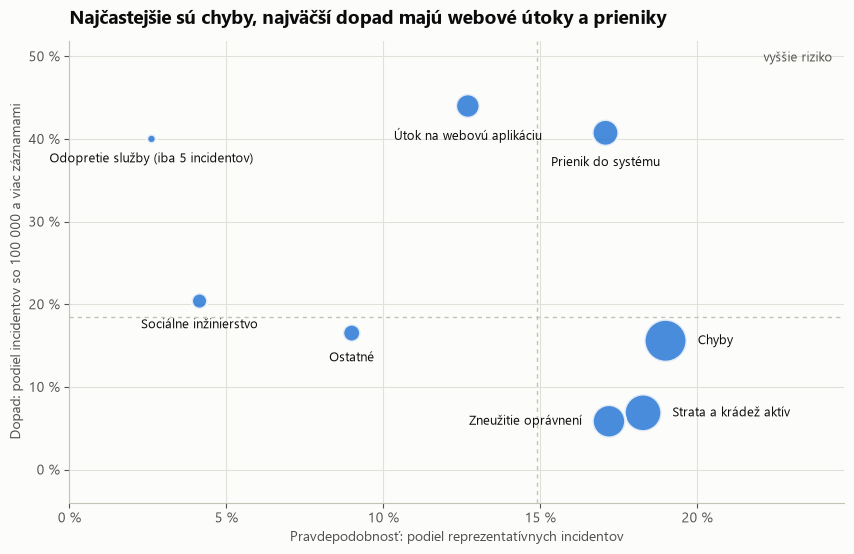

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
likelihood = pattern_stats["podiel incidentov %"]
impact = pattern_stats["vysoký dopad %"]
sizes = pattern_stats["incidenty so známym dopadom"]

ax.axvline(likelihood.median(), color=AXIS, linewidth=1, linestyle=(0, (3, 3)), zorder=1)
ax.axhline(impact.median(), color=AXIS, linewidth=1, linestyle=(0, (3, 3)), zorder=1)
areas = 40 + sizes / sizes.max() * 900
ax.scatter(likelihood, impact, s=areas, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=2, zorder=3)

# Popisky sú vedľa bodu tam, kde by sa inak prekrývali
SIDE = {"Chyby": "right", "Strata a krádež aktív": "right", "Zneužitie oprávnení": "left"}
for pattern in PATTERNS:
    radius = np.sqrt(areas[pattern] / np.pi)
    label = pattern if sizes[pattern] >= 30 else f"{pattern} (iba {sizes[pattern]} incidentov)"
    side = SIDE.get(pattern, "below")
    offset = {"right": (radius + 6, 0), "left": (-radius - 6, 0), "below": (0, -radius - 6)}[side]
    ax.annotate(label, (likelihood[pattern], impact[pattern]), xytext=offset, textcoords="offset points",
                ha={"right": "left", "left": "right", "below": "center"}[side],
                va="center" if side != "below" else "top", fontsize=9.5, color=INK)

ax.set_xlim(0, likelihood.max() * 1.3)
ax.set_ylim(-4, impact.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(plt.MultipleLocator(5))
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f} %")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0f} %")
ax.set_xlabel("Pravdepodobnosť: podiel reprezentatívnych incidentov")
ax.set_ylabel("Dopad: podiel incidentov so 100 000 a viac záznamami")
ax.text(likelihood.max() * 1.28, impact.max() * 1.15, "vyššie riziko", ha="right", va="top", color=INK_SECONDARY, fontsize=9)
ax.set_title('Najčastejšie sú chyby, najväčší dopad majú webové útoky a prieniky', loc="left", fontsize=14, fontweight="bold", pad=12)

fig.savefig(FIGURES_DIR / "1_matica_rizika.png")
plt.show()

### Vizualizácia 2: vzory útokov podľa odvetvia

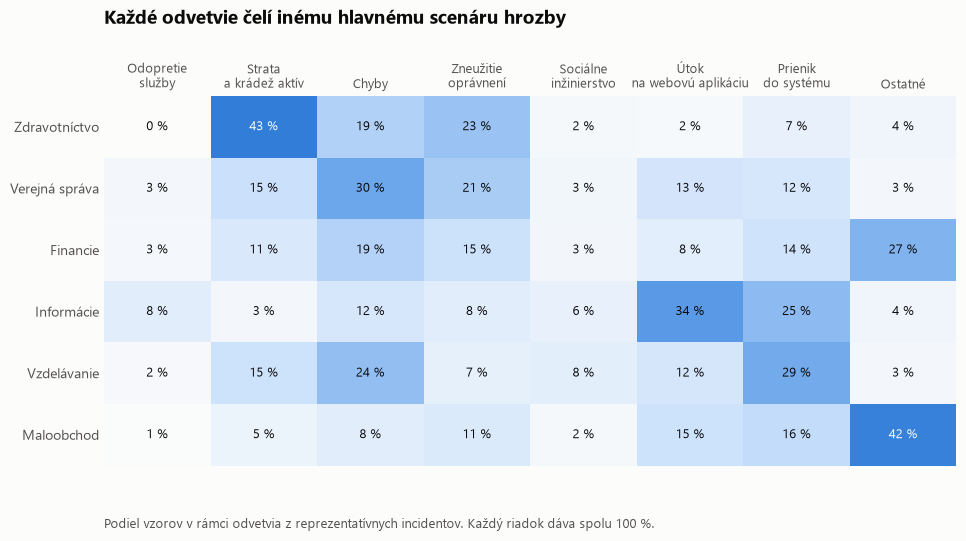

In [15]:
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
fig, ax = plt.subplots(figsize=(11, 4.8))
matrix = sector_pattern.to_numpy()
ax.imshow(matrix, cmap=blues, vmin=0, vmax=max(60, matrix.max()), aspect="auto")
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix[row, column]
        ax.text(column, row, f"{value:.0f} %", ha="center", va="center", fontsize=9.5,
                color="#ffffff" if value >= 40 else INK)

ax.set_xticks(range(len(PATTERNS)), [pattern.replace(" ", "\n", 1) for pattern in PATTERNS], fontsize=9)
ax.set_yticks(range(len(sector_pattern.index)), sector_pattern.index)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.xaxis.tick_top()
ax.set_title('Každé odvetvie čelí inému hlavnému scenáru hrozby', loc="left", fontsize=14, fontweight="bold", pad=52)
fig.text(0.125, -0.02, "Podiel vzorov v rámci odvetvia z reprezentatívnych incidentov. Každý riadok dáva spolu 100 %.",
         color=INK_SECONDARY, fontsize=9.5)

fig.savefig(FIGURES_DIR / "2_vzory_podla_odvetvia.png")
plt.show()

## 6. Podklady pre preskriptívnu analýzu

Každému vzoru útoku priraďujeme bezpečnostné opatrenia z rámca **CIS Controls v8**. Priradenie je naše a vychádza z obsahu jednotlivých opatrení a z odporúčaní správ Verizon DBIR. Náklady a účinnosť opatrení dataset neobsahuje, tie bude treba v preskriptívnej časti stanoviť ako predpoklady.

In [16]:
CIS = {
    1: ("Inventory and Control of Enterprise Assets", "prevencia"),
    3: ("Data Protection", "prevencia"),
    4: ("Secure Configuration of Enterprise Assets and Software", "prevencia"),
    5: ("Account Management", "prevencia"),
    6: ("Access Control Management", "prevencia"),
    7: ("Continuous Vulnerability Management", "prevencia"),
    8: ("Audit Log Management", "detekcia"),
    9: ("Email and Web Browser Protections", "prevencia"),
    10: ("Malware Defenses", "prevencia"),
    11: ("Data Recovery", "obnova"),
    12: ("Network Infrastructure Management", "prevencia"),
    13: ("Network Monitoring and Defense", "detekcia"),
    14: ("Security Awareness and Skills Training", "prevencia"),
    16: ("Application Software Security", "prevencia"),
    17: ("Incident Response Management", "reakcia"),
}
PATTERN_CONTROLS = {
    "Odopretie služby": [12, 13],
    "Strata a krádež aktív": [1, 3],
    "Chyby": [3, 4, 14],
    "Zneužitie oprávnení": [3, 5, 6, 8],
    "Sociálne inžinierstvo": [6, 9, 14],
    "Útok na webovú aplikáciu": [6, 7, 16],
    "Prienik do systému": [4, 7, 10, 11, 13],
    "Ostatné": [1, 17],
}

controls = pd.DataFrame(
    [(pattern, number, *CIS[number]) for pattern, numbers in PATTERN_CONTROLS.items() for number in numbers],
    columns=["vzor_utoku", "cis_cislo", "cis_nazov", "typ_opatrenia"],
)
assert set(controls["vzor_utoku"]) == set(PATTERNS)

pattern_share = representative["vzor_utoku"].value_counts(normalize=True)
coverage = (
    controls.assign(podiel=controls["vzor_utoku"].map(pattern_share))
    .groupby(["cis_cislo", "cis_nazov", "typ_opatrenia"], as_index=False)["podiel"].sum()
    .sort_values("podiel", ascending=False)
)
coverage["pokryté incidenty %"] = (coverage.pop("podiel") * 100).round(1)
print("Podiel reprezentatívnych incidentov, ktorých vzor dané opatrenie rieši:")
display(coverage.reset_index(drop=True))

Podiel reprezentatívnych incidentov, ktorých vzor dané opatrenie rieši:


,cis_cislo,cis_nazov,typ_opatrenia,pokryté incidenty %
0,3,Data Protection,prevencia,54.5
1,4,Secure Configuration of Enterprise Assets and ...,prevencia,36.1
2,6,Access Control Management,prevencia,34.0
3,7,Continuous Vulnerability Management,prevencia,29.8
4,1,Inventory and Control of Enterprise Assets,prevencia,27.3
5,14,Security Awareness and Skills Training,prevencia,23.1
6,13,Network Monitoring and Defense,detekcia,19.7
7,8,Audit Log Management,detekcia,17.2
8,5,Account Management,prevencia,17.2
9,10,Malware Defenses,prevencia,17.1


## 7. Uloženie výsledku

Vyčistené dáta a mapovanie opatrení sa ukladajú do `data/processed/`, ktorý git ignoruje.

In [17]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")
controls.to_csv(CONTROLS_PATH, index=False, encoding="utf-8")
print(f"Uložené: {OUTPUT_PATH} ({len(clean)} riadkov, {clean.shape[1]} stĺpcov), {CONTROLS_PATH} ({len(controls)} riadkov)")

Uložené: data\processed\vcdb_clean.csv (9961 riadkov, 50 stĺpcov), data\processed\vcdb_opatrenia_cis.csv (24 riadkov)


## 8. Zhrnutie

**Čistenie.** Z 10 047 incidentov zostalo 9 961:

| Úprava | Odstránené riadky |
| --- | ---: |
| Úplne zhodné kópie | 2 |
| Nepotvrdené incidenty | 81 |
| Stav analýzy `Ineligible` | 3 |

Vyčistená tabuľka má 50 stĺpcov. Z nich 6 270 incidentov je reprezentatívnych, teda náhodne vybraných a mimo hromadných zdrojov, a 5 097 incidentov má známy počet uniknutých záznamov.

**Zistenia z analýzy:**

- Externí aktéri stoja za 58,7 % reprezentatívnych incidentov, interní za 37,4 %. Interné incidenty sú najmä chyby (52,0 %) a zneužitie oprávnení (44,6 %), nie útoky.
- Najčastejšie vzory sú chyby (19,0 %), strata a krádež aktív (18,3 %), zneužitie oprávnení (17,2 %) a prienik do systému (17,1 %).
- Častosť a dopad spolu nesúvisia. Útoky na webové aplikácie a prieniky do systému vedú k úniku aspoň 100 000 záznamov v 44,0 % a 40,7 % prípadov, kým zneužitie oprávnení iba v 5,8 % a strata a krádež v 6,9 %.
- Každé odvetvie má iný hlavný scenár. V zdravotníctve dominuje strata a krádež aktív (43,2 %), v odvetví informácií útoky na webové aplikácie (34,3 %) a v maloobchode kategória ostatné (41,8 %), ktorú tvoria najmä skimmery na platobných termináloch.
- Zneužitie oprávnení sa odhalí najneskôr. Pri incidentoch so známym časom odhalenia trvalo v 50,3 % prípadov roky.

**Ako dataset podporí ďalšie časti:**

| Časť | Čo dataset poskytuje |
| --- | --- |
| Predikčná analýza | Cieľ `dopad` s triedami `nízky` (2 431), `stredný` (1 783) a `vysoký` (883). Vstupom sú aktér, spôsob útoku, aktívum, odvetvie, veľkosť organizácie a typ dát. Na rozdelenie dát slúži stĺpec `skupina`, aby incidenty z jedného zdroja neboli v tréningu aj v teste. |
| Preskriptívna analýza | Pravdepodobnosť vzoru útoku z reprezentatívnych incidentov, predikovaný dopad a mapovanie vzorov na opatrenia CIS Controls v8. Najširšie pokrytie má CIS 3 Data Protection, ktoré rieši vzory 54,5 % incidentov. |

Cieľ `unik_dat` sa na predikciu nehodí, lebo hodnotu `No` má iba 79 incidentov. Verejné databázy zachytávajú takmer výlučne incidenty, pri ktorých k úniku došlo.

**Obmedzenia:**

- VCDB obsahuje iba verejne známe incidenty a 73 % obetí je z USA. Skryté incidenty a incidenty bez povinnosti hlásenia v ňom chýbajú.
- Dopad je meraný počtom záznamov, nie peniazmi. Finančnú stratu uvádza iba 324 incidentov.
- Popis incidentu často priamo uvádza počet dotknutých osôb (1 004 popisov), preto nesmie byť vstupom predikcie dopadu.
- Vzor útoku je zjednodušením klasifikácie DBIR a priradenie opatrení je naše. Náklady a účinnosť opatrení treba v preskriptívnej časti doplniť ako predpoklady.
- Od roku 2022 obsahuje VCDB málo náhodne vybraných incidentov. Rok 2023 tvorí najmä útok na MOVEit, preto sa dáta nehodia na vývoj v čase po roku 2021.